In [1]:
# ============================================================
# IMPORTS AND CONFIGURATION
# ============================================================

import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists() and (PROJECT_DIR.parent / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "nox_target_transform"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# ============================================================
# LOAD AND PREPARE DATA
# ============================================================

files = sorted(DATA_DIR.glob("gt_*.csv"))
if not files:
    raise FileNotFoundError(f"No gt_*.csv files found in {DATA_DIR.resolve()}")

frames = []
for file in files:
    frame = pd.read_csv(file)
    frame["Year"] = int(file.stem.split("_")[-1])
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)

feature_cols = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]
required_cols = feature_cols + ["NOX", "Year"]

missing_cols = [col for col in required_cols if col not in data.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=required_cols).reset_index(drop=True)

if (data["NOX"] <= 0).any():
    raise ValueError("Log-transformed models require strictly positive NOX values.")

development_data = data[data["Year"] <= 2014].copy().reset_index(drop=True)
comparison_data = data[data["Year"] == 2015].copy().reset_index(drop=True)

print("Development observations:", len(development_data))
print("2015 comparison observations:", len(comparison_data))

Development observations: 29349
2015 comparison observations: 7384


count    36733.000000
mean        65.293067
std         11.678357
min         25.905000
25%         57.162000
50%         63.849000
75%         71.548000
max        119.910000
Name: NOX, dtype: float64
Skewness: 1.0267788505165127
Kurtosis: 2.0375914079765147


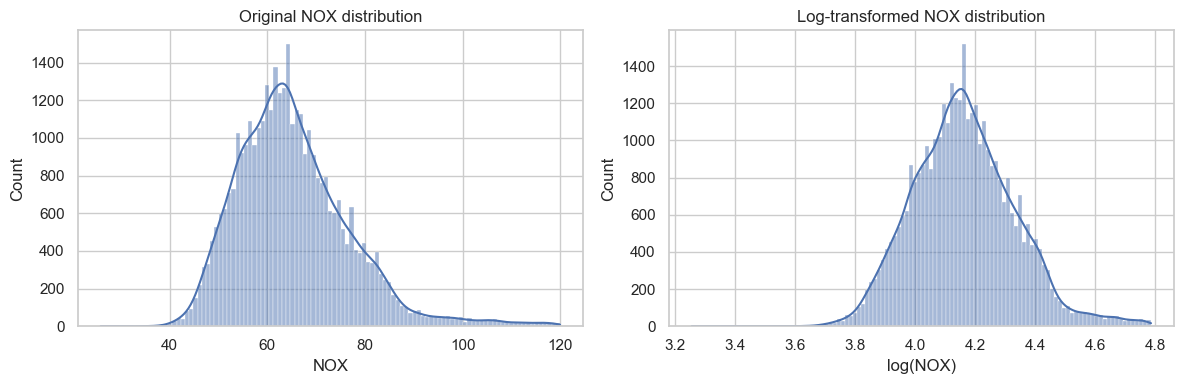

In [3]:
# ============================================================
# INSPECT NOX DISTRIBUTION
# ============================================================

print(data["NOX"].describe())
print("Skewness:", data["NOX"].skew())
print("Kurtosis:", data["NOX"].kurtosis())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data["NOX"], kde=True, ax=axes[0])
axes[0].set_title("Original NOX distribution")
axes[0].set_xlabel("NOX")

sns.histplot(np.log(data["NOX"]), kde=True, ax=axes[1])
axes[1].set_title("Log-transformed NOX distribution")
axes[1].set_xlabel("log(NOX)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nox_distribution_comparison.png", dpi=300)
plt.show()

In [4]:
# ============================================================
# CHRONOLOGICAL TRAINING AND VALIDATION SPLIT
# ============================================================

fit_data = development_data[development_data["Year"] <= 2013].copy().reset_index(drop=True)
validation_data = development_data[development_data["Year"] == 2014].copy().reset_index(drop=True)

X_fit = fit_data[feature_cols]
y_fit = fit_data["NOX"]
X_validation = validation_data[feature_cols]
y_validation = validation_data["NOX"]

print("Training observations (2011–2013):", len(fit_data))
print("Validation observations (2014):", len(validation_data))

Training observations (2011–2013): 22191
Validation observations (2014): 7158


In [5]:
# ============================================================
# DEFINE MODELS
# ============================================================

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Log Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Log Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Polynomial Ridge Degree 2": Pipeline([
        ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ])
}

log_target_models = {
    "Log Linear Regression",
    "Log Ridge Regression"
}

In [6]:
# ============================================================
# FIT MODELS AND EVALUATE ON 2014 VALIDATION DATA
# ============================================================

validation_predictions = {}
validation_rows = []
fitted_validation_models = {}

for model_name, model in models.items():
    target_for_fit = np.log(y_fit) if model_name in log_target_models else y_fit

    model.fit(X_fit, target_for_fit)
    raw_prediction = model.predict(X_validation)

    y_prediction = (
        np.exp(raw_prediction)
        if model_name in log_target_models
        else raw_prediction
    )

    validation_predictions[model_name] = y_prediction
    fitted_validation_models[model_name] = model

    validation_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_validation, y_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_validation, y_prediction)),
        "R2": r2_score(y_validation, y_prediction)
    })

    print(f"Completed: {model_name}")

validation_results = pd.DataFrame(validation_rows).sort_values("RMSE")
display(validation_results.round(4))
validation_results.to_csv(OUTPUT_DIR / "nox_validation_model_comparison_2014.csv", index=False)

Completed: Linear Regression
Completed: Log Linear Regression
Completed: Log Ridge Regression
Completed: Polynomial Ridge Degree 2


,Model,MAE,RMSE,R2
2,Log Ridge Regression,11.1680,12.4978,-0.5710
0,Linear Regression,11.5559,12.8482,-0.6604
1,Log Linear Regression,11.7883,13.1043,-0.7272
3,Polynomial Ridge Degree 2,16.2621,17.3680,-2.0340


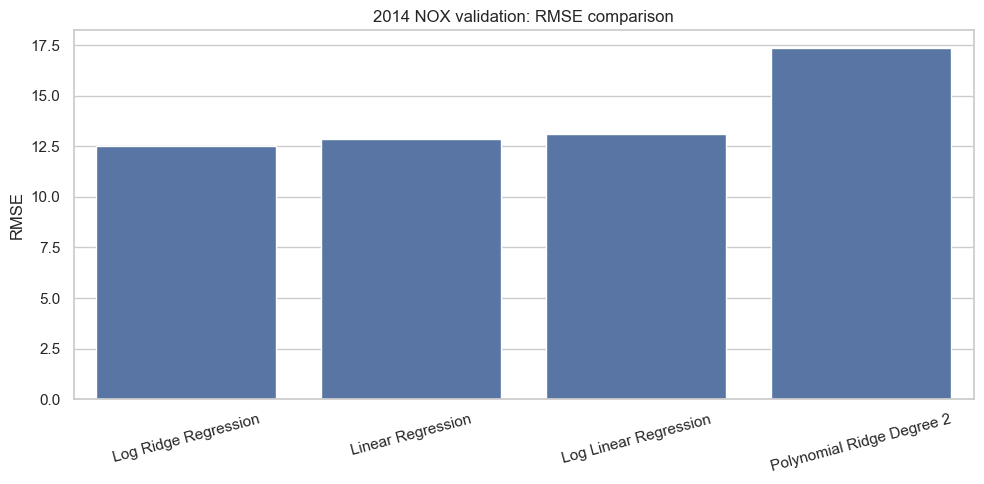

In [7]:
# ============================================================
# PLOT 2014 VALIDATION RMSE
# ============================================================

plt.figure(figsize=(10, 5))
sns.barplot(data=validation_results, x="Model", y="RMSE")
plt.title("2014 NOX validation: RMSE comparison")
plt.xlabel("")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nox_validation_rmse_2014.png", dpi=300)
plt.show()

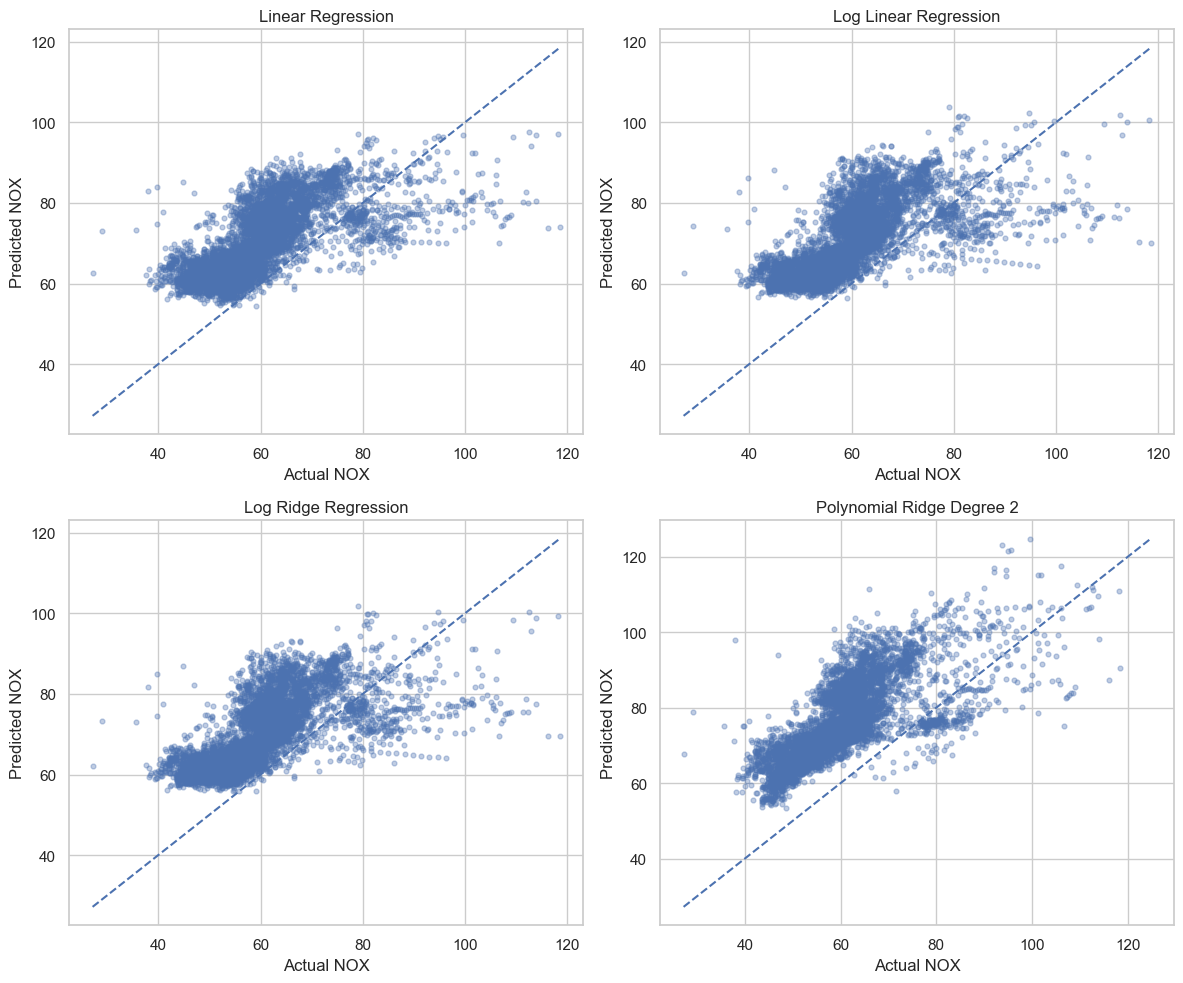

In [8]:
# ============================================================
# PLOT 2014 ACTUAL VS PREDICTED
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (model_name, y_prediction) in zip(axes, validation_predictions.items()):
    ax.scatter(y_validation, y_prediction, alpha=0.35, s=12)
    lower = min(y_validation.min(), np.min(y_prediction))
    upper = max(y_validation.max(), np.max(y_prediction))
    ax.plot([lower, upper], [lower, upper], linestyle="--")
    ax.set_title(model_name)
    ax.set_xlabel("Actual NOX")
    ax.set_ylabel("Predicted NOX")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nox_validation_actual_vs_predicted_2014.png", dpi=300)
plt.show()

In [9]:
# ============================================================
# SELECT MODEL USING 2014 VALIDATION ONLY
# ============================================================

best_model_name = validation_results.iloc[0]["Model"]
print("Selected model:", best_model_name)
print("2014 validation RMSE:", validation_results.iloc[0]["RMSE"])
print("2015 data is not used for model selection.")

Selected model: Log Ridge Regression
2014 validation RMSE: 12.4978174345436
2015 data is not used for model selection.


In [10]:
# ============================================================
# RETRAIN SELECTED MODEL ON ALL 2011–2014 DATA
# ============================================================

final_model = models[best_model_name]

target_for_final_fit = (
    np.log(development_data["NOX"])
    if best_model_name in log_target_models
    else development_data["NOX"]
)

final_model.fit(development_data[feature_cols], target_for_final_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['AT','AP','AH',...,'TIT','TAT','CDP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [11]:
# ============================================================
# EVALUATE SELECTED MODEL ON 2015 COMPARISON DATA
# ============================================================

X_comparison = comparison_data[feature_cols]
y_comparison = comparison_data["NOX"]

raw_comparison_prediction = final_model.predict(X_comparison)
comparison_prediction = (
    np.exp(raw_comparison_prediction)
    if best_model_name in log_target_models
    else raw_comparison_prediction
)

comparison_metrics = pd.DataFrame([{
    "Model": best_model_name,
    "MAE": mean_absolute_error(y_comparison, comparison_prediction),
    "RMSE": np.sqrt(mean_squared_error(y_comparison, comparison_prediction)),
    "R2": r2_score(y_comparison, comparison_prediction)
}])

display(comparison_metrics.round(4))
comparison_metrics.to_csv(OUTPUT_DIR / "nox_selected_model_2015_metrics.csv", index=False)

,Model,MAE,RMSE,R2
0,Log Ridge Regression,7.8417,9.9841,0.1956


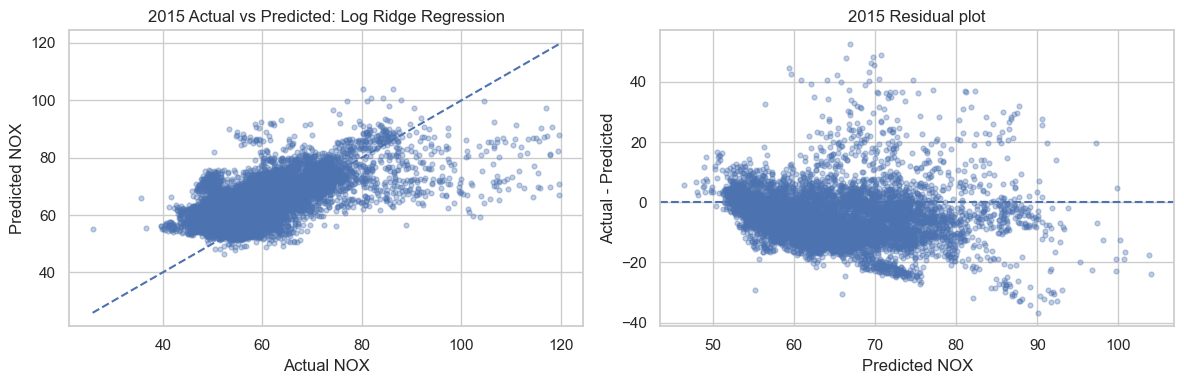

In [12]:
# ============================================================
# PLOT 2015 ACTUAL VS PREDICTED AND RESIDUALS
# ============================================================

residuals = y_comparison.to_numpy() - comparison_prediction

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_comparison, comparison_prediction, alpha=0.35, s=12)
lower = min(y_comparison.min(), np.min(comparison_prediction))
upper = max(y_comparison.max(), np.max(comparison_prediction))
axes[0].plot([lower, upper], [lower, upper], linestyle="--")
axes[0].set_title(f"2015 Actual vs Predicted: {best_model_name}")
axes[0].set_xlabel("Actual NOX")
axes[0].set_ylabel("Predicted NOX")

axes[1].scatter(comparison_prediction, residuals, alpha=0.35, s=12)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("2015 Residual plot")
axes[1].set_xlabel("Predicted NOX")
axes[1].set_ylabel("Actual - Predicted")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nox_selected_model_2015_diagnostics.png", dpi=300)
plt.show()

In [13]:
# ============================================================
# EXPORT PREDICTIONS AND MODEL RESULTS
# ============================================================

prediction_output = comparison_data[["Year"]].copy()
prediction_output["NOX_actual"] = y_comparison.to_numpy()
prediction_output["NOX_predicted"] = comparison_prediction
prediction_output["Residual"] = residuals

prediction_output.to_csv(OUTPUT_DIR / "nox_selected_model_2015_predictions.csv", index=False)

settings = pd.DataFrame([
    {"Item": "Selected model", "Value": best_model_name},
    {"Item": "Training period for validation", "Value": "2011–2013"},
    {"Item": "Validation period", "Value": "2014"},
    {"Item": "Final development period", "Value": "2011–2014"},
    {"Item": "Comparison period", "Value": "2015"},
    {"Item": "Polynomial degree", "Value": 2},
    {"Item": "Ridge alpha", "Value": 10.0}
])

settings.to_csv(OUTPUT_DIR / "nox_model_settings.csv", index=False)

print("Notebook completed. Results saved to:", OUTPUT_DIR.resolve())

Notebook completed. Results saved to: C:\Users\devra\Music\gas-turbine-ml\outputs\nox_target_transform
